In [2]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
from tensorflow import keras


In [21]:
from tensorflow.keras import losses
from tensorflow.keras import callbacks
from tensorflow.keras import layers,models
from tensorflow.keras import optimizers
from tensorflow.keras.models import Sequential
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout,Input,BatchNormalization

In [6]:
from tensorflow.keras import layers

print("Layers imported successfully!")


Layers imported successfully!


In [5]:
import tensorflow as tf
print(tf.__version__)

from tensorflow.keras import layers

2.21.0


In [11]:
import kagglehub
path = kagglehub.dataset_download("salmansajid05/oral-diseases")

Using Colab cache for faster access to the 'oral-diseases' dataset.


In [12]:
for dirname, _, filenames in os.walk('/kaggle/input'):
    print(dirname, len(filenames))

/kaggle/input 0
/kaggle/input/oral-diseases 0
/kaggle/input/oral-diseases/Data caries 0
/kaggle/input/oral-diseases/Data caries/Data caries 0
/kaggle/input/oral-diseases/Data caries/Data caries/caries orignal data set 0
/kaggle/input/oral-diseases/Data caries/Data caries/caries orignal data set/done 219
/kaggle/input/oral-diseases/Data caries/Data caries/caries augmented data set 0
/kaggle/input/oral-diseases/Data caries/Data caries/caries augmented data set/preview 2382
/kaggle/input/oral-diseases/Mouth Ulcer 0
/kaggle/input/oral-diseases/Mouth Ulcer/Mouth Ulcer 0
/kaggle/input/oral-diseases/Mouth Ulcer/Mouth Ulcer/Mouth_Ulcer_augmented_DataSet 0
/kaggle/input/oral-diseases/Mouth Ulcer/Mouth Ulcer/Mouth_Ulcer_augmented_DataSet/preview 2541
/kaggle/input/oral-diseases/Mouth Ulcer/Mouth Ulcer/ulcer original dataset 0
/kaggle/input/oral-diseases/Mouth Ulcer/Mouth Ulcer/ulcer original dataset/ulcer original dataset 265
/kaggle/input/oral-diseases/Tooth Discoloration 0
/kaggle/input/oral-d

In [13]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

base = "/kaggle/input/oral-diseases"

folders = {
    "Caries": f"{base}/Data caries/Data caries/caries orignal data set/done",
    "Mouth Ulcer": f"{base}/Mouth Ulcer/Mouth Ulcer/ulcer original dataset/ulcer original dataset",
    "Tooth Discoloration": f"{base}/Tooth Discoloration/Tooth Discoloration /tooth discoloration original dataset/tooth discoloration original dataset",
    "Gingivitis": f"{base}/Gingivitis/Gingivitis",
    "Calculus": f"{base}/Calculus/Calculus",
    "Hypodontia": f"{base}/hypodontia/hypodontia",
}

rows = []
for label, path in folders.items():
    for f in os.listdir(path):
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            rows.append((os.path.join(path, f), label))

df = pd.DataFrame(rows, columns=["filepath", "label"])
print(df["label"].value_counts())
print("Total:", len(df))

label
Gingivitis             2349
Calculus               1296
Hypodontia             1251
Mouth Ulcer             265
Caries                  219
Tooth Discoloration     183
Name: count, dtype: int64
Total: 5563


In [26]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=42)
print("train/val/test:", len(train_df), len(val_df), len(test_df))

classes = sorted(df["label"].unique())
weights = compute_class_weight("balanced", classes=np.array(classes), y=train_df["label"])
class_weight = {i: w for i, w in enumerate(weights)}
print(classes)
print(class_weight)

train/val/test: 3894 834 835
['Calculus', 'Caries', 'Gingivitis', 'Hypodontia', 'Mouth Ulcer', 'Tooth Discoloration']
{0: np.float64(0.7155457552370452), 1: np.float64(4.241830065359477), 2: np.float64(0.39476885644768855), 3: np.float64(0.7408675799086758), 4: np.float64(3.489247311827957), 5: np.float64(5.0703125)}


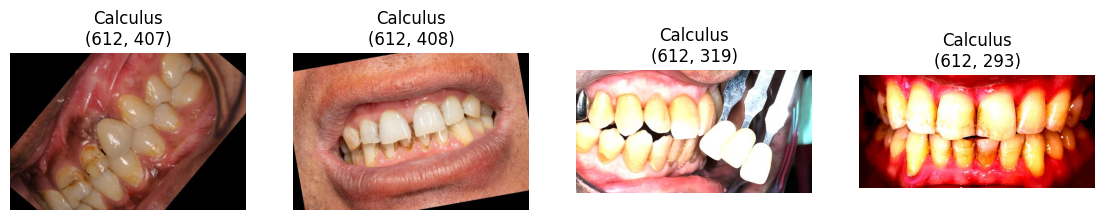

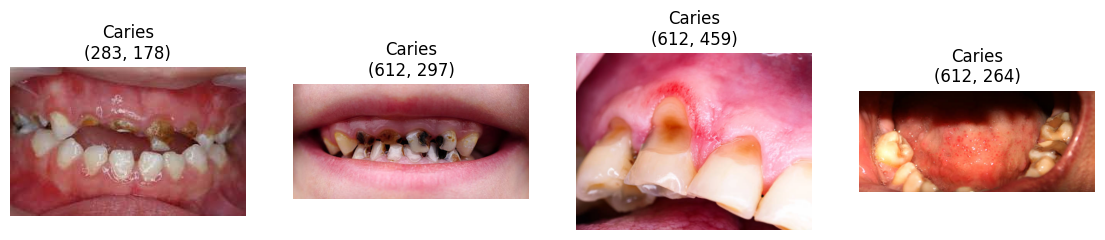

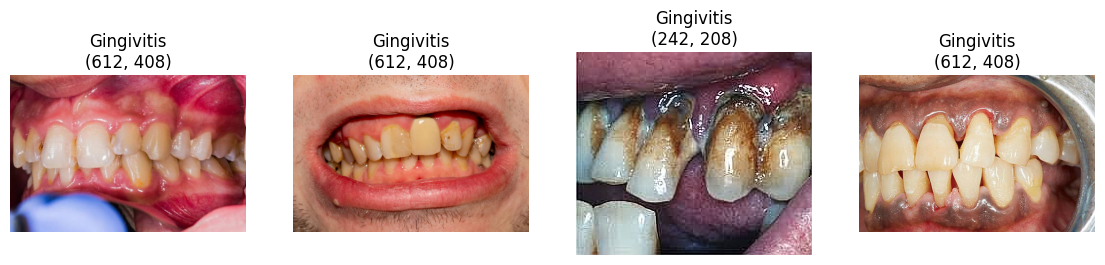

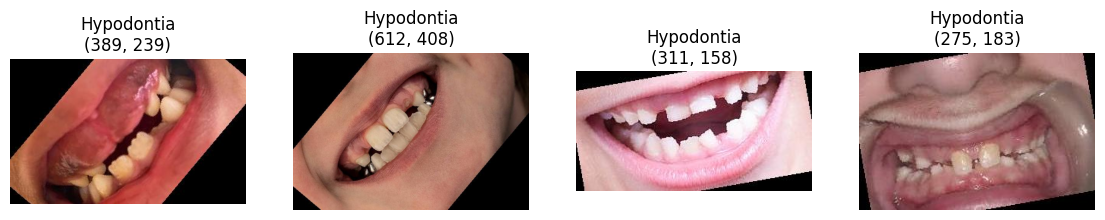

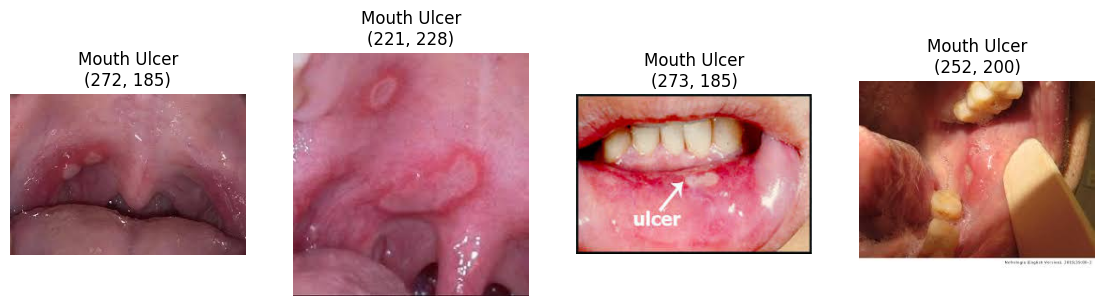

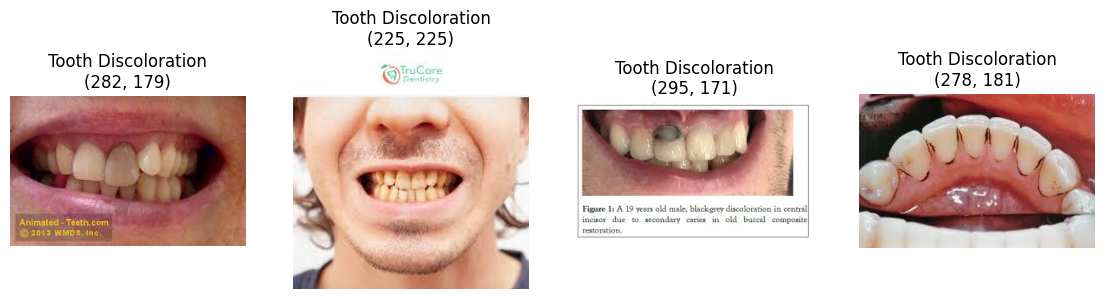

In [27]:
for label in classes:
    sample = df[df["label"] == label].sample(4, random_state=1)
    plt.figure(figsize=(14, 3.5))
    for i, (_, r) in enumerate(sample.iterrows()):
        img = Image.open(r["filepath"])
        plt.subplot(1, 4, i + 1)
        plt.imshow(img)
        plt.title(f"{label}\n{img.size}")
        plt.axis("off")
    plt.show()


In [32]:
IMG_SIZE = 224
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE
class_to_idx = {c: i for i, c in enumerate(classes)}

def load_img(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, label

def make_ds(d, training):
    paths = d["filepath"].values
    labels = d["label"].map(class_to_idx).values
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_img, num_parallel_calls=AUTOTUNE)
    ds = ds.cache()
    if training:
        ds = ds.shuffle(len(d), seed=42)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(train_df, training=True)
val_ds = make_ds(val_df, training=False)
test_ds = make_ds(test_df, training=False)

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.06),
    layers.RandomZoom(0.15),
    layers.RandomBrightness(0.2),
    layers.RandomContrast(0.2),
], name="augmentation")

xb, yb = next(iter(train_ds))
print(xb.shape, yb[:10].numpy())


(32, 224, 224, 3) [2 2 0 2 0 0 5 3 2 2]


In [28]:
num_classes = len(classes)

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    data_augmentation,            # التعديلات العشوائية (بتشتغل وقت التدريب بس)
    layers.Rescaling(1./255),

    # Block 1
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    # Block 2
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    # Block 3
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation="softmax"),
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,132,966 (50.10 MB)

 Trainable params: 13,132,966 (50.10 MB)

 Non-trainable params: 0 (0.00 B)

In [29]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    class_weight=class_weight,
    callbacks=[early_stop],
)

model.save("/kaggle/working/custom_cnn.keras")

Epoch 1/30
122/122 ━━━━━━━━━━━━━━━━━━━━ 42s 237ms/step - accuracy: 0.1995 - loss: 1.8086 - val_accuracy: 0.4113 - val_loss: 1.4952
Epoch 2/30
122/122 ━━━━━━━━━━━━━━━━━━━━ 20s 162ms/step - accuracy: 0.1998 - loss: 1.7689 - val_accuracy: 0.2866 - val_loss: 1.5764
Epoch 3/30
122/122 ━━━━━━━━━━━━━━━━━━━━ 20s 164ms/step - accuracy: 0.2563 - loss: 1.7281 - val_accuracy: 0.2638 - val_loss: 1.5796
Epoch 4/30
122/122 ━━━━━━━━━━━━━━━━━━━━ 22s 176ms/step - accuracy: 0.3765 - loss: 1.5985 - val_accuracy: 0.4628 - val_loss: 1.3234
Epoch 5/30
122/122 ━━━━━━━━━━━━━━━━━━━━ 21s 171ms/step - accuracy: 0.3754 - loss: 1.4444 - val_accuracy: 0.2206 - val_loss: 1.5238
Epoch 6/30
122/122 ━━━━━━━━━━━━━━━━━━━━ 21s 169ms/step - accuracy: 0.3675 - loss: 1.4320 - val_accuracy: 0.4868 - val_loss: 1.1489
Epoch 7/30
122/122 ━━━━━━━━━━━━━━━━━━━━ 21s 169ms/step - accuracy: 0.4232 - loss: 1.3292 - val_accuracy: 0.5276 - val_loss: 1.1685
Epoch 8/30
122/122 ━━━━━━━━━━━━━━━━━━━━ 21s 171ms/step - accuracy: 0.4420 - loss: 1

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/custom_cnn.keras'

In [30]:
import os
model.save("custom_cnn.keras")
print(os.getcwd(), os.listdir("."))

/content ['.config', 'custom_cnn.keras', 'sample_data']


27/27 ━━━━━━━━━━━━━━━━━━━━ 5s 188ms/step - accuracy: 0.5976 - loss: 0.9439
Test accuracy: 0.5976048111915588
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 76ms/step
                     precision    recall  f1-score   support

           Calculus       0.44      0.42      0.43       195
             Caries       0.21      0.30      0.25        33
         Gingivitis       0.68      0.62      0.65       353
         Hypodontia       0.73      0.77      0.75       188
        Mouth Ulcer       0.78      0.90      0.83        39
Tooth Discoloration       0.23      0.33      0.27        27

           accuracy                           0.60       835
          macro avg       0.51      0.56      0.53       835
       weighted avg       0.61      0.60      0.60       835



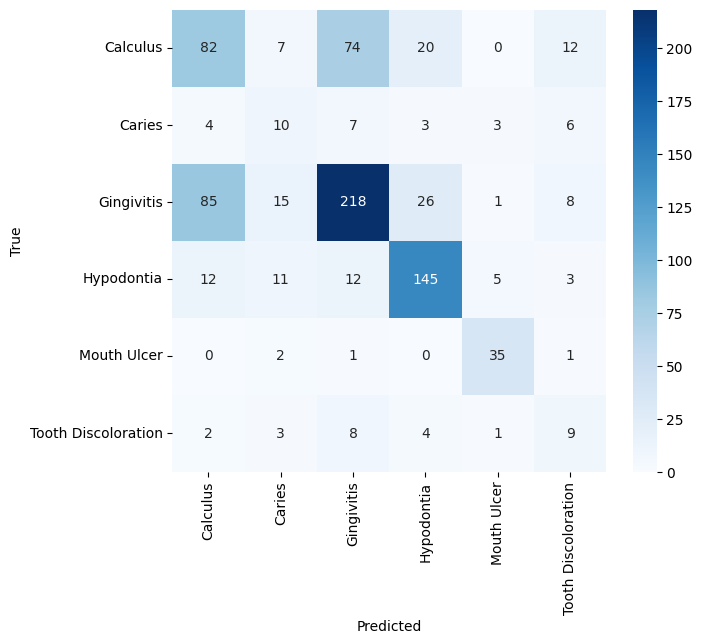

In [31]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

test_loss, test_acc = model.evaluate(test_ds)
print("Test accuracy:", test_acc)

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(model.predict(test_ds), axis=1)

print(classification_report(y_true, y_pred, target_names=classes))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=classes, yticklabels=classes, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

In [33]:
from sklearn.metrics import accuracy_score, f1_score
from tensorflow.keras.callbacks import EarlyStopping

def train_pretrained(base, preprocess):
    base.trainable = False
    inputs = layers.Input(shape=(224, 224, 3))
    x = data_augmentation(inputs)
    x = preprocess(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(len(classes), activation="softmax")(x)
    m = tf.keras.Model(inputs, outputs)
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    m.fit(train_ds, validation_data=val_ds, epochs=12, class_weight=class_weight,
          callbacks=[EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)])
    y_true = np.concatenate([y.numpy() for _, y in test_ds])
    y_pred = np.argmax(m.predict(test_ds), axis=1)
    print("Test accuracy:", accuracy_score(y_true, y_pred))
    print("Macro F1:", f1_score(y_true, y_pred, average="macro"))
    return m

base1 = tf.keras.applications.MobileNetV2(input_shape=(224,224,3), include_top=False, weights="imagenet")
model_mobilenet = train_pretrained(base1, tf.keras.applications.mobilenet_v2.preprocess_input)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/12
122/122 ━━━━━━━━━━━━━━━━━━━━ 20s 98ms/step - accuracy: 0.4561 - loss: 1.5325 - val_accuracy: 0.6487 - val_loss: 0.9341
Epoch 2/12
122/122 ━━━━━━━━━━━━━━━━━━━━ 9s 76ms/step - accuracy: 0.5984 - loss: 0.9870 - val_accuracy: 0.6355 - val_loss: 0.8926
Epoch 3/12
122/122 ━━━━━━━━━━━━━━━━━━━━ 9s 77ms/step - accuracy: 0.6423 - loss: 0.8395 - val_accuracy: 0.6571 - val_loss: 0.7987
Epoch 4/12
122/122 ━━━━━━━━━━━━━━━━━━━━ 11s 92ms/step - accuracy: 0.6597 - loss: 0.7815 - val_accuracy: 0.7062 - val_loss: 0.6813
Epoch 5/12
122/122 ━━━━━━━━━━━━━━━━━━━━ 10s 78ms/step - accuracy: 0.6715 - loss: 0.7480 - val_accuracy: 0.6691 - val_loss: 0.8052
Epoch 6/12
122/122 ━━━━━━━━━━━━━━━━━━━━ 10s 80ms/step - accuracy: 0.6965 - loss: 0.6568 - val_accuracy: 0.7158 - val_loss: 0.6382
Epoch 7/12
122/122 ━━━━━━━━━━━━━━━━━━━━ 10s 80ms/step - accuracy: 0.6864 - loss: 0.6639 - val_accuracy: 0.6942 - val_loss: 0.7233
Epoch 8/12
122/122 ━━━━━━━━━━━━━━━━━━━━ 10s

In [34]:
base2 = tf.keras.applications.EfficientNetB0(input_shape=(224,224,3), include_top=False, weights="imagenet")
model_efficient = train_pretrained(base2, lambda x: x)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/12
122/122 ━━━━━━━━━━━━━━━━━━━━ 26s 127ms/step - accuracy: 0.4895 - loss: 1.3538 - val_accuracy: 0.6391 - val_loss: 0.9854
Epoch 2/12
122/122 ━━━━━━━━━━━━━━━━━━━━ 13s 103ms/step - accuracy: 0.6184 - loss: 0.9644 - val_accuracy: 0.6775 - val_loss: 0.8655
Epoch 3/12
122/122 ━━━━━━━━━━━━━━━━━━━━ 13s 105ms/step - accuracy: 0.6505 - loss: 0.8550 - val_accuracy: 0.7098 - val_loss: 0.7847
Epoch 4/12
122/122 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - accuracy: 0.6787 - loss: 0.7788 - val_accuracy: 0.6643 - val_loss: 0.8386
Epoch 5/12
122/122 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - accuracy: 0.6736 - loss: 0.7413 - val_accuracy: 0.6871 - val_loss: 0.7541
Epoch 6/12
122/122 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - accuracy: 0.6888 - loss: 0.7053 - val_accuracy: 0.7122 - val_loss: 0.6915
Epoch 7/12
122/122 ━━━━━━━━━━━━━━━━━━━━ 13s 104ms/step - accuracy: 0.6972 - loss: 0.6815 - val_accuracy: 0.7254 - val_loss: 0.6782
Epoch 8/12
122/122 ━━━━━━━━━━━━━

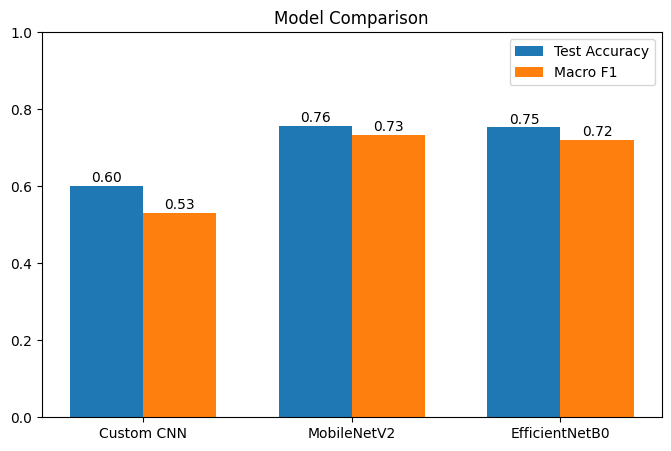

In [35]:
import matplotlib.pyplot as plt
import numpy as np

names = ["Custom CNN", "MobileNetV2", "EfficientNetB0"]
acc = [0.60, 0.757, 0.753]
f1 = [0.53, 0.733, 0.720]

x = np.arange(len(names))
w = 0.35

plt.figure(figsize=(8, 5))
b1 = plt.bar(x - w/2, acc, w, label="Test Accuracy")
b2 = plt.bar(x + w/2, f1, w, label="Macro F1")

for bars in (b1, b2):
    for b in bars:
        plt.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01,
                 f"{b.get_height():.2f}", ha="center")

plt.xticks(x, names)
plt.ylim(0, 1)
plt.title("Model Comparison")
plt.legend()
plt.show()

In [36]:
def train_tuned(lr, dropout):
    base = tf.keras.applications.MobileNetV2(input_shape=(224,224,3), include_top=False, weights="imagenet")
    base.trainable = False
    inputs = layers.Input(shape=(224, 224, 3))
    x = data_augmentation(inputs)
    x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(len(classes), activation="softmax")(x)
    m = tf.keras.Model(inputs, outputs)
    m.compile(optimizer=tf.keras.optimizers.Adam(lr),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    m.fit(train_ds, validation_data=val_ds, epochs=12, class_weight=class_weight,
          callbacks=[EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)],
          verbose=0)
    val_acc = m.evaluate(val_ds, verbose=0)[1]
    y_true = np.concatenate([y.numpy() for _, y in test_ds])
    y_pred = np.argmax(m.predict(test_ds, verbose=0), axis=1)
    return m, val_acc, accuracy_score(y_true, y_pred), f1_score(y_true, y_pred, average="macro")

results = []
tuned_models = {}
for lr, dr in [(1e-4, 0.3), (1e-3, 0.5), (1e-4, 0.5)]:
    m, va, ta, f1 = train_tuned(lr, dr)
    tuned_models[(lr, dr)] = (m, va)
    results.append((lr, dr, round(va, 3), round(ta, 3), round(f1, 3)))
    print("done:", lr, dr)

print(pd.DataFrame(results, columns=["LR", "Dropout", "Val Acc", "Test Acc", "Test Macro F1"]))

done: 0.0001 0.3
done: 0.001 0.5
done: 0.0001 0.5
       LR  Dropout  Val Acc  Test Acc  Test Macro F1
0  0.0001      0.3    0.670     0.675          0.620
1  0.0010      0.5    0.743     0.749          0.721
2  0.0001      0.5    0.644     0.667          0.611


Val accuracy: 0.7158273458480835
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 64ms/step
                     precision    recall  f1-score   support

           Calculus       0.66      0.53      0.59       195
             Caries       0.49      0.61      0.54        33
         Gingivitis       0.74      0.84      0.78       353
         Hypodontia       0.91      0.85      0.88       188
        Mouth Ulcer       0.93      0.95      0.94        39
Tooth Discoloration       0.71      0.63      0.67        27

           accuracy                           0.76       835
          macro avg       0.74      0.73      0.73       835
       weighted avg       0.76      0.76      0.75       835



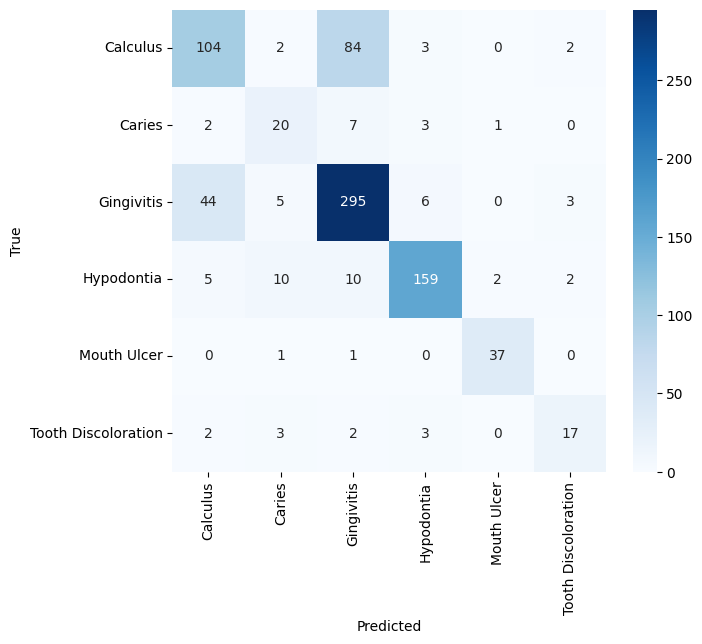

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:
final_model = model_mobilenet

print("Val accuracy:", final_model.evaluate(val_ds, verbose=0)[1])

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(final_model.predict(test_ds), axis=1)
print(classification_report(y_true, y_pred, target_names=classes))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=classes, yticklabels=classes, cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.show()

final_model.save("final_model.keras")
from google.colab import files
files.download("final_model.keras")

In [38]:
model_mobilenet.save_weights("mobilenet_frozen.weights.h5")

base1.trainable = True
for layer in base1.layers[:-30]:
    layer.trainable = False

model_mobilenet.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model_mobilenet.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weight,
    callbacks=[EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)],
)

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(model_mobilenet.predict(test_ds), axis=1)
print("Test accuracy:", accuracy_score(y_true, y_pred))
print("Macro F1:", f1_score(y_true, y_pred, average="macro"))

Epoch 1/15
122/122 ━━━━━━━━━━━━━━━━━━━━ 39s 131ms/step - accuracy: 0.5478 - loss: 1.0858 - val_accuracy: 0.7338 - val_loss: 0.6334
Epoch 2/15
122/122 ━━━━━━━━━━━━━━━━━━━━ 11s 93ms/step - accuracy: 0.6305 - loss: 0.8662 - val_accuracy: 0.7338 - val_loss: 0.6287
Epoch 3/15
122/122 ━━━━━━━━━━━━━━━━━━━━ 12s 95ms/step - accuracy: 0.6574 - loss: 0.7444 - val_accuracy: 0.7386 - val_loss: 0.6210
Epoch 4/15
122/122 ━━━━━━━━━━━━━━━━━━━━ 12s 96ms/step - accuracy: 0.6739 - loss: 0.7189 - val_accuracy: 0.7422 - val_loss: 0.6064
Epoch 5/15
122/122 ━━━━━━━━━━━━━━━━━━━━ 12s 97ms/step - accuracy: 0.6913 - loss: 0.6704 - val_accuracy: 0.7470 - val_loss: 0.5963
Epoch 6/15
122/122 ━━━━━━━━━━━━━━━━━━━━ 12s 99ms/step - accuracy: 0.6944 - loss: 0.6207 - val_accuracy: 0.7578 - val_loss: 0.5887
Epoch 7/15
122/122 ━━━━━━━━━━━━━━━━━━━━ 12s 102ms/step - accuracy: 0.6975 - loss: 0.5962 - val_accuracy: 0.7578 - val_loss: 0.5879
Epoch 8/15
122/122 ━━━━━━━━━━━━━━━━━━━━ 12s 102ms/step - accuracy: 0.7237 - loss: 0.5576

In [39]:
model_mobilenet.save("final_model.keras")

test_load = tf.keras.models.load_model("final_model.keras")
print("Loaded OK")
print("TF version:", tf.__version__)

from google.colab import files
files.download("final_model.keras")

Loaded OK
TF version: 2.21.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip -q install gradio
import gradio as gr

final_model = model_mobilenet

def predict(img):
    if img is None:
        return None
    img = tf.image.resize(tf.cast(img, tf.float32), (224, 224))
    probs = final_model.predict(tf.expand_dims(img, 0), verbose=0)[0]
    return {classes[i]: float(probs[i]) for i in range(len(classes))}

header = """
# 🦷 Oral Diseases Image Classification
Upload a photo of the mouth or teeth, and the AI will predict the most likely condition.

**Detectable conditions:** Calculus · Caries · Gingivitis · Hypodontia · Mouth Ulcer · Tooth Discoloration
"""

about = """
**Model:** MobileNetV2 (transfer learning + fine-tuning)
**Test accuracy:** ~79% · **Macro F1:** ~0.77
⚠️ *Student project for educational purposes only. Not a medical diagnosis. Please consult a dentist.*
"""

with gr.Blocks(theme=gr.themes.Soft(primary_hue="teal")) as demo:
    gr.Markdown(header)
    with gr.Row():
        with gr.Column():
            inp = gr.Image(label="Upload an image", type="numpy", height=350)
            with gr.Row():
                clear = gr.ClearButton(value="Clear")
                btn = gr.Button("🔍 Analyze", variant="primary")
        with gr.Column():
            out = gr.Label(num_top_classes=3, label="Prediction")
    gr.Markdown(about)

    btn.click(predict, inp, out)
    clear.add([inp, out])

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://ba49b1f225228ef46d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
